In [1]:
import warnings
from copy import deepcopy
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# The pipeline lives in main2.py so the script and the notebook cannot drift.
# Run `python main2.py` to regenerate everything below, or set the RUN_ flag to
# drive it from here.
from main2 import (
    ERRORS_PATH,
    LABELS,
    METHOD_COLORS,
    METHODS,
    RESULTS_DIR,
    TUNING_PATH,
    make_config,
    run_monte_carlo,
    tune,
    weak_design,
)
from mfsindy.experiments import load_tuning
from mfsindy.plots import bubble_hist, tuning_heatmap

warnings.filterwarnings("ignore")
sns.set(context="paper", style="white")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

cfg = make_config()


# Lorenz Part 2 — Intra-trajectory GLS

This notebook compares three different strategies for properly fit a SINDy model on a trajectory characterized by heteroskedastik noise: 
- *No weighting* (`WeakPDELibrary`)
- *Variance GLS* (`WeightedWeakPDELibrary`, weights = variance_scaled)
- *Unitary GLS* (`WeightedWeakPDELibrary`, weights = 1, only correlation effect)

## Governing equations

The classical Lorenz--63 system is given by

$$
\begin{aligned}
\dot{x} &= \sigma (y - x), \\
\dot{y} &= x(\rho - z) - y, \\
\dot{z} &= xy - \beta z.
\end{aligned}
$$

We use the standard parameter values $(\sigma, \rho, \beta) = (10, 28, 8/3)$.

Let $U=(x,y,z)^\top$ denote the system state. We model additive perturbation error by adding a zero-mean random noise term $\epsilon$ to $U$, that is,
$$
U^{\mathrm{noisy}} = U + \epsilon.
$$
Where
$$
\mathbb{E}[\epsilon] = 0,
\qquad
\mathrm{Var}(\epsilon) \propto \alpha^2 \|U\|^2.
$$

## Trajectories

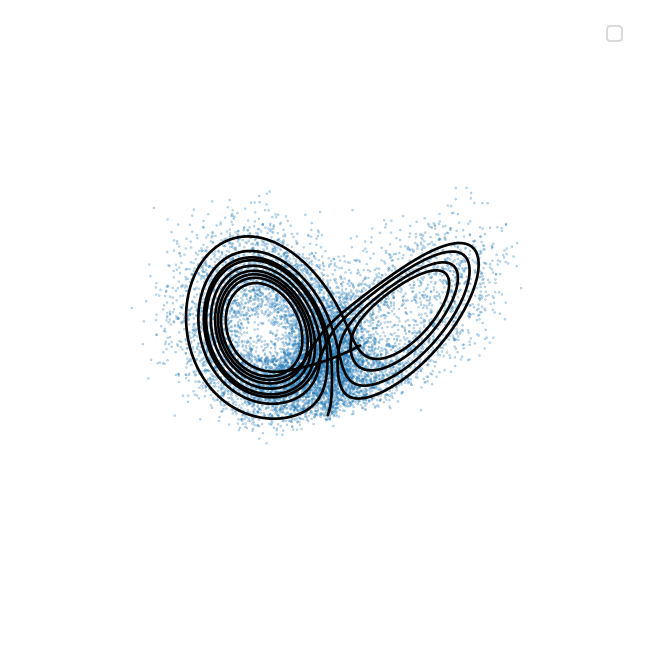

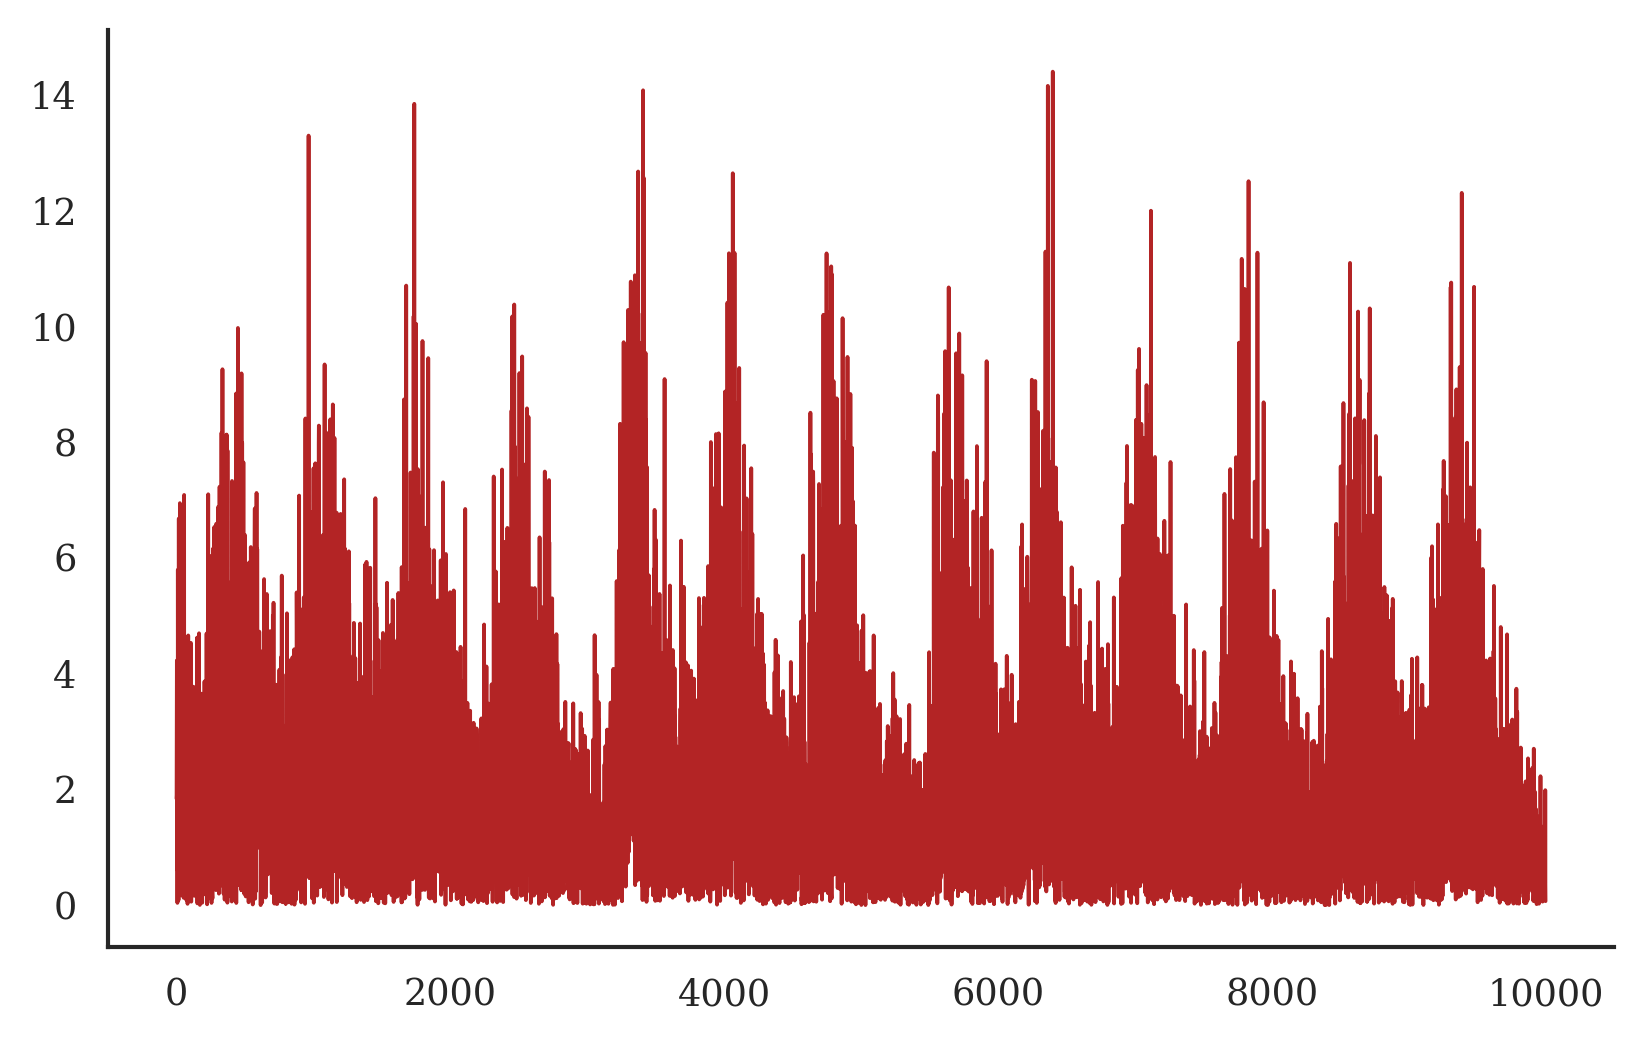

In [2]:
from mfsindy.cases.lorenz import generate_lorenz_trajectory
from mfsindy.cases.lorenz_plots import plot_trajectories_additive_noise, plot_residuals

y0 = np.array([10.0,-10.0,30.0])
_, X_true, _ = generate_lorenz_trajectory(
    y0=y0,
    noise_level=0.0,
    seed=0,
    T=10
)
X_noisy = plot_trajectories_additive_noise(x_true=X_true,alpha=0.1)
plot_residuals(x_true=X_true, x_noisy=X_noisy)


## Hyperparameter selection

Every rung is tuned separately, so a difference between weightings is not a
difference in how well each was configured. There is one trajectory here rather
than the held-out set Part I uses, so the search draws its own at a disjoint
seed and keeps the last 20% of it in time; the validation library is built
**unweighted** and scored with an unweighted weak $R^2$, which keeps the
weighting under test out of its own measurement -- it decides the fit, not the
score. The validation support is fixed for the whole grid at the narrowest width
whose noise ceiling clears the floor, so every candidate is ranked against the
same target.

$\kappa$ is reported beside each selection but never restricts the grid: it
governs the covariance model, so a support where it is large is one where the
weighting is expected to help least. That is a result to report, not a point to
drop.


In [3]:
# What each weighting fits. All four rungs share one set of test functions, so
# any difference between them is the weighting alone. diag_spread is 1 for the
# unit-variance covariance by construction; above 1 it is the heteroscedasticity
# the diagonal rung weights by.
print(weak_design(cfg).to_string())


                  K  duplicates_dropped  diag_spread     cov_cond  cov_rank_deficit
method                                                                             
No weighting   1846                 154          NaN          NaN               NaN
Ones GLS       1846                 154     1.000000   614.729179               0.0
Variance diag  1846                 154    52.179007  8846.593169               0.0
Variance GLS   1846                 154    52.179007  8846.593169               0.0


In [ ]:
# Set to True to run the search here; leave False to read what main2.py wrote.
RUN_TUNING = False

if RUN_TUNING:
    artifacts = tune(cfg)
else:
    artifacts = load_tuning(TUNING_PATH)

selections = artifacts.selections
score_table = artifacts.score_table
kappa_table = artifacts.kappa_table

print("validation system:", artifacts.fixed["validation_support"])
print()
print(kappa_table.to_string(index=False))
print()

selected = pd.DataFrame({r: s.best_params for r, s in selections.items()}).T
selected["kappa"] = pd.Series(
    artifacts.fixed["kappa_diagnostic"]["kappa_at_selection"]
)
print(selected.to_string())


### Tuning surface

The selection is one cell of this grid; the surface is what says whether it
means anything. A flat rung was not really tuned, a spike will not survive a
reseed, and a best on an edge is asking for a wider grid.


In [ ]:
tuning_heatmap(
    score_table,
    selections=selections,
    rungs=METHODS,
    x="stlsq_threshold",
    y="H_xt",
    save_path="results/tuning_2",
)


## Run

In [4]:
# Set to True to run the Monte Carlo here; leave False to read what main2.py
# wrote. Running it overwrites the CSV below.
RUN_EXPERIMENT = False

if RUN_EXPERIMENT:
    run_monte_carlo(cfg, selections)


## Errors

In [5]:
df_errors = pd.read_csv(ERRORS_PATH)


def metric_values(metric: str) -> dict[str, np.ndarray]:
    return {
        m: df_errors[
            (df_errors["method"] == m) & (df_errors["metric"] == metric)
        ]["value"].to_numpy()
        for m in METHODS
    }


L1_errors = metric_values("L1")
L0_errors = metric_values("L0")

summary = pd.DataFrame(
    {
        "median L1": {m: float(np.median(L1_errors[m])) for m in METHODS},
        "median L0": {m: float(np.median(L0_errors[m])) for m in METHODS},
        "runs": {m: int(L1_errors[m].size) for m in METHODS},
    }
)
print(summary.to_string())


               median L1  median L0  runs
No weighting    3.085786   1.142857   100
Ones GLS        2.078662   0.857143   100
Variance diag   2.478746   1.000000   100
Variance GLS    1.802026   0.714286   100


### L1 Error

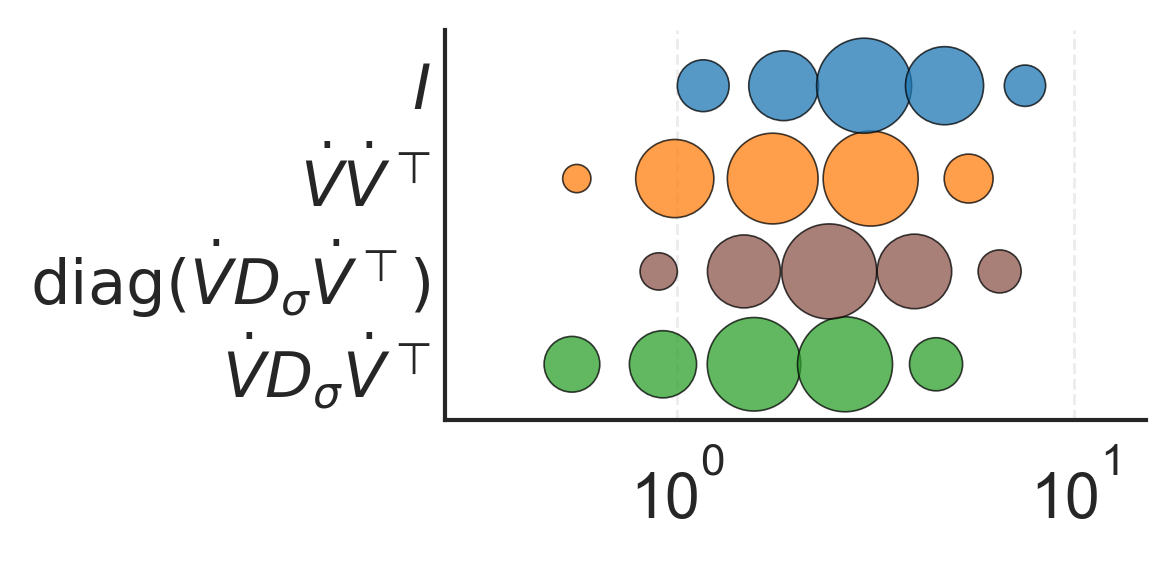

In [8]:
# Each row is binned over its own values and the axis is logarithmic, since the
# weightings differ by orders of magnitude; the limits are left to the function,
# as an additive pad can cross zero on a log axis.
plot_order = list(reversed(METHODS))

bubble_hist(
    errors_dict=L1_errors,
    n_bins=5,
    log_x=True,
    models_order=plot_order,
    colors=METHOD_COLORS,
    labels=[LABELS[m] for m in plot_order],
    save_path="results/l1_2",
)


### L0 Error

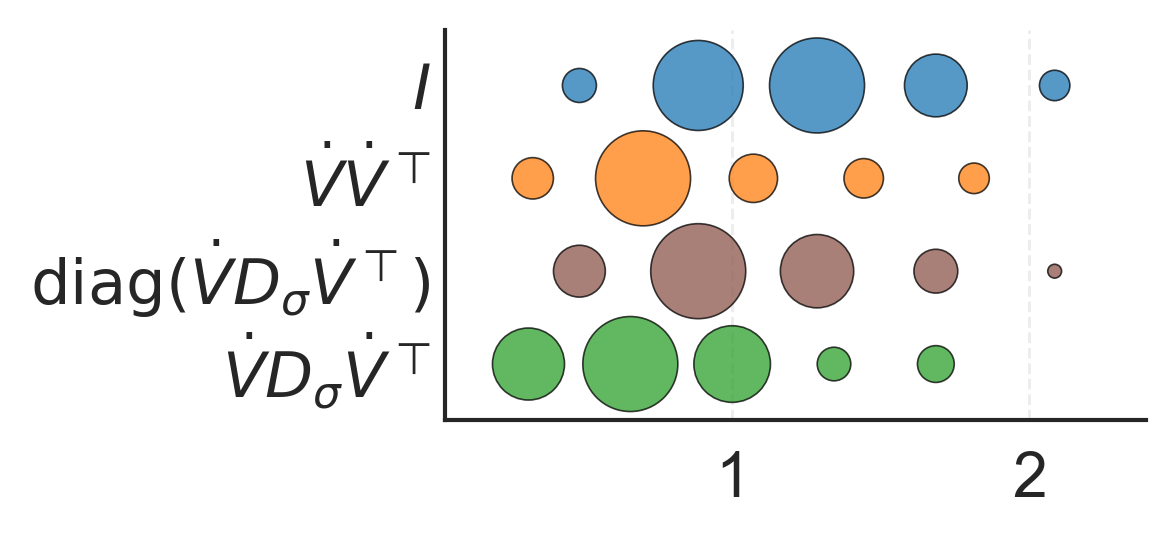

In [9]:
# Linear axis here: support error is legitimately zero when a weighting recovers
# the support exactly, which a log axis cannot show.
all_l0_values = np.concatenate([np.asarray(L0_errors[m], dtype=float) for m in METHODS])
xmin = float(np.min(all_l0_values)) - 0.001
xmax = float(np.max(all_l0_values)) + 0.001
pad = 0.05 * (xmax - xmin if xmax > xmin else 1.0)

bubble_hist(
    errors_dict=L0_errors,
    n_bins=5,
    models_order=plot_order,
    colors=METHOD_COLORS,
    labels=[LABELS[m] for m in plot_order],
    xlim=(xmin - pad, xmax + pad),
    save_path="results/l0_2",
)
